# Projeto Final PSI3472 — Planejamento de Voos Nacionais com Algoritmo Genético

**Fluxo de avaliação de um indivíduo**

```
GENOMA ──decodificar──► TAB_AV (voos + aeronaves) ──alocar──► TAB_AP (passageiros) ──► FITNESS
  ▲                                                                                        │
  └──────────────── seleção / cruzamento / mutação atuam só sobre o genoma ◄───────────────┘
```

**Organização do notebook**

| Seção | Conteúdo | Status |
|---|---|---|
| 0 | Dados do enunciado (TAB_TV, TAB_OD) e parâmetros | ✅ |
| 1 | Genoma: estrutura, codificador, decodificador e tabelas (TAB_AV, TAB_PV, TAB_MV) | ✅ |
| 2 | Alocação de passageiros nos voos (TAB_AP) | ✅ |
| 3 | Função de avaliação (fitness) | ✅ |
| 4+ | Algoritmo genético e simulações | a implementar |

In [1]:
import random
import time
from dataclasses import dataclass, field

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

---
## 0. Dados e parâmetros

Parâmetros do enunciado e as hipóteses adotadas pelo grupo onde o enunciado é omisso.

In [2]:
# ---- Parâmetros do enunciado ----
N_AERONAVES        = 400   # frota disponível
CAPACIDADE         = 200   # passageiros por aeronave
PRIMEIRA_DECOLAGEM = 6     # 06:00
ULTIMA_DECOLAGEM   = 21    # 21:00 — última decolagem permitida (chegadas podem ser depois)
ESCALA_MIN_H       = 1     # escala mínima do passageiro: 60 min (usada na Seção 2)

# ---- Parâmetro do alocador (Seção 2) ----
MAX_ESCALAS = 2            # "escala": nº máximo de escalas por passageiro; acima disso, remanescente

# ---- Hipóteses do grupo (não especificadas no enunciado) ----
TURNAROUND_H = 1           # tempo mínimo da aeronave em solo entre pousar e decolar de novo

# ---- Parâmetros do genoma ----
MAX_TRECHOS = 8            # nº máximo de voos por aeronave no dia (enunciado: referência de 2 a 8)
ESPERA_MAX  = 3            # espera extra máxima (h) sorteada para cada trecho na geração de genomas

### 0.1 Aeroportos e TAB_TV — tempos de voo (min)
Linha = origem, coluna = destino. A diagonal é 0 (não há voo de um aeroporto para ele mesmo).
Os totais de linha/coluna são conferidos contra os do PDF para evitar erro de digitação.

In [3]:
AEROPORTOS = ["MA", "BE", "FO", "NA", "RE", "SA", "BR", "BH", "CI", "RJ", "SP", "CR", "FL", "PA"]
NOMES = {
    "MA": "Manaus", "BE": "Belém", "FO": "Fortaleza", "NA": "Natal", "RE": "Recife",
    "SA": "Salvador", "BR": "Brasília", "BH": "Belo Horizonte", "CI": "Cuiabá",
    "RJ": "Rio de Janeiro", "SP": "São Paulo", "CR": "Curitiba", "FL": "Florianópolis",
    "PA": "Porto Alegre",
}

_TV = [
#     MA   BE   FO   NA   RE   SA   BR   BH   CI   RJ   SP   CR   FL   PA
    [  0, 120, 180, 180, 180, 180, 180, 240, 180, 300, 300, 300, 360, 360],  # MA
    [120,   0, 120, 120, 120, 180, 180, 240, 180, 240, 240, 300, 300, 360],  # BE
    [180, 120,   0,  60,  60, 120, 180, 180, 240, 240, 240, 300, 300, 360],  # FO
    [180, 120,  60,   0,  60, 120, 180, 180, 240, 240, 240, 300, 300, 360],  # NA
    [180, 120,  60,  60,   0, 120, 180, 180, 240, 180, 180, 240, 240, 300],  # RE
    [180, 180, 120, 120, 120,   0, 120, 120, 180, 120, 120, 180, 180, 240],  # SA
    [180, 180, 180, 180, 180, 120,   0,  60,  60, 120, 120, 180, 180, 240],  # BR
    [240, 240, 180, 180, 180, 120,  60,   0, 120,  60,  60, 120, 120, 180],  # BH
    [180, 180, 240, 240, 240, 180,  60, 120,   0, 180, 180, 180, 180, 240],  # CI
    [300, 240, 240, 240, 180, 120, 120,  60, 180,   0,  60, 120, 120, 180],  # RJ
    [300, 240, 240, 240, 180, 120, 120,  60, 180,  60,   0,  60,  60, 120],  # SP
    [300, 300, 300, 300, 240, 180, 180, 120, 180, 120,  60,   0,  60,  60],  # CR
    [360, 300, 300, 300, 240, 180, 180, 120, 180, 120,  60,  60,   0,  60],  # FL
    [360, 360, 360, 360, 300, 240, 240, 180, 240, 180, 120,  60,  60,   0],  # PA
]
TAB_TV = pd.DataFrame(_TV, index=AEROPORTOS, columns=AEROPORTOS)

# Conferência com os totais do PDF
_TOTAIS_TV = [3060, 2700, 2580, 2580, 2280, 1980, 1980, 1860, 2400, 2160, 1980, 2400, 2460, 3060]
assert TAB_TV.sum(axis=1).tolist() == _TOTAIS_TV
assert TAB_TV.sum(axis=0).tolist() == _TOTAIS_TV
# Obs.: o PDF mostra total geral 34480, mas a soma dos próprios totais de linha dá 33480 (erro no PDF).
assert TAB_TV.values.sum() == 33480
assert (TAB_TV.values % 60 == 0).all(), "todos os tempos devem ser múltiplos de 60 min"

# Acesso rápido em HORAS: TV_H[origem][destino]
TV_H = {o: {d: int(TAB_TV.at[o, d]) // 60 for d in AEROPORTOS if d != o} for o in AEROPORTOS}

TAB_TV

,MA,BE,FO,NA,RE,SA,BR,BH,CI,RJ,SP,CR,FL,PA
MA,0,120,180,180,180,180,180,240,180,300,300,300,360,360
BE,120,0,120,120,120,180,180,240,180,240,240,300,300,360
FO,180,120,0,60,60,120,180,180,240,240,240,300,300,360
NA,180,120,60,0,60,120,180,180,240,240,240,300,300,360
RE,180,120,60,60,0,120,180,180,240,180,180,240,240,300
SA,180,180,120,120,120,0,120,120,180,120,120,180,180,240
BR,180,180,180,180,180,120,0,60,60,120,120,180,180,240
BH,240,240,180,180,180,120,60,0,120,60,60,120,120,180
CI,180,180,240,240,240,180,60,120,0,180,180,180,180,240
RJ,300,240,240,240,180,120,120,60,180,0,60,120,120,180


### 0.2 TAB_OD — demanda diária de passageiros (origem → destino)
Cada passageiro é contado uma vez pela viagem completa (com ou sem escala).

In [4]:
_OD = [
#      MA    BE    FO    NA    RE    SA    BR    BH    CI    RJ    SP    CR    FL    PA
    [   0,  800,  900,  600,  900,  900, 1600,  800,  500, 1700, 2200,  800,  400,  600],  # MA
    [ 900,    0, 1100,  800,  700, 1100, 1400,  900,  300, 1800, 1800,  800,  400,  500],  # BE
    [ 600,  900,    0, 1200, 1200, 1200, 1700, 1000,  400, 2300, 1600,  900,  600,  800],  # FO
    [ 400,  700, 1000,    0,  900, 1200, 1400,  600,  600, 1400, 1600,  900,  600,  700],  # NA
    [ 600,  800, 1500, 1100,    0, 1400, 1900,  700,  900, 2600, 2400, 1100,  900,  900],  # RE
    [ 400,  500, 1600, 1500, 1400,    0, 2100, 1100, 1100, 2400, 2500, 1100, 1100, 1100],  # SA
    [ 900, 1100, 1800, 1400, 1700, 2100,    0, 1500, 1700, 3600, 7800, 1300, 1200, 1400],  # BR
    [ 400,  900, 1100,  600, 1200,  800, 2200,    0,  800, 1400, 1800,  700,  500,  600],  # BH
    [ 500,  500,  900,  800,  900,  600, 1000,  700,    0, 1000, 1400,  500,  400,  500],  # CI
    [1200,  900, 2000, 1500, 2100, 2400, 3700, 1900, 1800,    0, 8100, 1700, 1500, 1700],  # RJ
    [1500, 1600, 3000, 1800, 3100, 2600, 5900,  600, 1700, 7000,    0, 3000, 2100, 2200],  # SP
    [ 300,  800, 1000,  700,  800, 1200, 1400,  900,  600, 1600, 1600,    0,  700, 1100],  # CR
    [ 300,  700,  900, 1400,  900, 1300, 1600, 1100,  600, 2000, 1800, 1000,    0,  700],  # FL
    [ 300,  600,  800, 1100,  500, 1100, 1500,  900,  400, 1900, 1500,  700,  600,    0],  # PA
]
TAB_OD = pd.DataFrame(_OD, index=AEROPORTOS, columns=AEROPORTOS)

# Conferência com os totais do PDF
assert TAB_OD.sum(axis=1).tolist() == [12700, 12500, 14400, 12000, 16800, 17900, 27500,
                                       13000, 9700, 30500, 36100, 12700, 14300, 11900]
assert TAB_OD.sum(axis=0).tolist() == [8300, 10800, 17600, 14500, 16300, 17900, 27400,
                                       12700, 11400, 30700, 36100, 14500, 11000, 12800]
assert TAB_OD.values.sum() == 242_000

# Acesso rápido: DEMANDA[(origem, destino)]
TRECHOS = [(o, d) for o in AEROPORTOS for d in AEROPORTOS if o != d]   # 182 pares O-D
DEMANDA = {(o, d): int(TAB_OD.at[o, d]) for o, d in TRECHOS}

# Referência: nº mínimo de voos diretos para levar toda a demanda sem escalas
voos_min = sum(-(-n // CAPACIDADE) for n in DEMANDA.values())
print(f"Demanda total: {sum(DEMANDA.values()):,} passageiros/dia em {len(TRECHOS)} pares O-D")
print(f"Voos diretos mínimos (ceil(demanda/200) por par): {voos_min}  "
      f"| capacidade de referência: {N_AERONAVES} aeronaves x 5 voos = {N_AERONAVES * 5}")

TAB_OD

Demanda total: 242,000 passageiros/dia em 182 pares O-D
Voos diretos mínimos (ceil(demanda/200) por par): 1255  | capacidade de referência: 400 aeronaves x 5 voos = 2000


,MA,BE,FO,NA,RE,SA,BR,BH,CI,RJ,SP,CR,FL,PA
MA,0,800,900,600,900,900,1600,800,500,1700,2200,800,400,600
BE,900,0,1100,800,700,1100,1400,900,300,1800,1800,800,400,500
FO,600,900,0,1200,1200,1200,1700,1000,400,2300,1600,900,600,800
NA,400,700,1000,0,900,1200,1400,600,600,1400,1600,900,600,700
RE,600,800,1500,1100,0,1400,1900,700,900,2600,2400,1100,900,900
SA,400,500,1600,1500,1400,0,2100,1100,1100,2400,2500,1100,1100,1100
BR,900,1100,1800,1400,1700,2100,0,1500,1700,3600,7800,1300,1200,1400
BH,400,900,1100,600,1200,800,2200,0,800,1400,1800,700,500,600
CI,500,500,900,800,900,600,1000,700,0,1000,1400,500,400,500
RJ,1200,900,2000,1500,2100,2400,3700,1900,1800,0,8100,1700,1500,1700


---
## 1. Genoma — codificação, decodificação e tabelas

### Estrutura do genoma

```
genoma = [ gene_A001, gene_A002, ..., gene_A400 ]          (um gene por aeronave)

gene   = base | (destino₁, espera₁) | (destino₂, espera₂) | ... | (destino₈, espera₈)
```

- **base**: aeroporto onde a aeronave amanhece (primeiro voo parte daí, a partir das 06:00).
- **destino**: próximo aeroporto. O valor especial `FIM` encerra o dia daquela aeronave.
- **espera**: horas extras em solo antes de decolar, além do turnaround.

**Decisões de projeto**

- A **origem** de cada voo não está no genoma: é sempre o destino do voo anterior ⇒ é impossível uma aeronave "se teletransportar", mesmo após cruzamento/mutação.
- Os **horários** também não estão no genoma: são calculados pelo decodificador
  (`partida = disponível + espera`, `chegada = partida + TV`, `disponível = chegada + turnaround`) ⇒ nunca ficam inconsistentes.
- Trechos que partiriam depois das 21:00 são **inativos** (ignorados pelo decodificador), como "DNA não-expresso". Podem voltar a ser ativos após uma mutação que antecipe horários.
- **Passageiros não estão no genoma**: o nº de passageiros de cada voo é consequência da demanda e é calculado pelo alocador (Seção 2).

### 1.1 O gene da aeronave

In [5]:
FIM = None   # destino especial: a aeronave encerra o dia


@dataclass
class GeneAeronave:
    """Gene de uma aeronave: onde ela amanhece e a sequência de (destino, espera)."""
    base: str
    trechos: list   # list[tuple[str | None, int]] com MAX_TRECHOS elementos

    def copia(self):
        return GeneAeronave(self.base, list(self.trechos))

    def __str__(self):
        partes = [self.base]
        for destino, espera in self.trechos:
            if destino is FIM:
                partes.append("FIM")
                break
            partes.append(f"{destino}+{espera}")
        return " | ".join(partes)


def mostrar_genoma(genoma, n=5):
    for i, gene in enumerate(genoma[:n], start=1):
        print(f"A{i:03d}: {gene}")
    if len(genoma) > n:
        print(f"... ({len(genoma) - n} genes omitidos)")

### 1.2 Fenótipo: `Voo`, `Aeronave` e `Plano`

O fenótipo é o que o genoma "produz". Cada indivíduo tem o seu próprio `Plano`.
`Voo.ocupacao` fica vazio aqui e será preenchido pelo alocador na Seção 2, no formato
`{(origem_final, destino_final): n_passageiros}`.

In [6]:
def fmt_hora(h):
    """Formata hora inteira; chegadas após meia-noite aparecem como (+1d)."""
    return f"{h:02d}:00" if h < 24 else f"{h - 24:02d}:00(+1d)"


@dataclass(eq=False)
class Voo:
    id: str            # "V0001"
    aeronave: str      # "A001"
    ordem: int         # posição do voo na sequência da aeronave (1, 2, ...)
    origem: str
    destino: str
    partida: int       # hora cheia
    chegada: int       # hora cheia (pode passar de 24)
    ocupacao: dict = field(default_factory=dict)   # {(orig_final, dest_final): n} — Seção 2

    @property
    def total(self):
        return sum(self.ocupacao.values())

    @property
    def livres(self):
        return CAPACIDADE - self.total

    @property
    def duracao_min(self):
        return (self.chegada - self.partida) * 60

    @property
    def rotulo(self):
        """Rótulo no estilo do PDF (ex.: A1V2 = aeronave 1, 2º voo)."""
        return f"A{int(self.aeronave[1:])}V{self.ordem}"

    def __repr__(self):
        return (f"{self.id}[{self.aeronave} {self.origem}→{self.destino} "
                f"{fmt_hora(self.partida)}-{fmt_hora(self.chegada)} {self.total}pax]")


@dataclass(eq=False)
class Aeronave:
    id: str
    base: str
    capacidade: int = CAPACIDADE
    voos: list = field(default_factory=list)

    @property
    def usada(self):
        return bool(self.voos)

    @property
    def horas_voo(self):
        return sum(v.chegada - v.partida for v in self.voos)


@dataclass
class Plano:
    aeronaves: list          # list[Aeronave]
    voos: list               # list[Voo]  (TAB_AV)
    voos_por_trecho: dict    # {(origem, destino): [Voo, ...] ordenados por partida} — índice p/ Seção 2

### 1.3 Decodificador: genoma → `Plano` (TAB_AV)

In [7]:
def decodificar(genoma):
    """Transforma o genoma em voos concretos (com horários) atribuídos às aeronaves."""
    aeronaves, voos, voos_por_trecho = [], [], {}

    for i, gene in enumerate(genoma, start=1):
        av = Aeronave(f"A{i:03d}", gene.base)
        local, disponivel = gene.base, PRIMEIRA_DECOLAGEM

        for destino, espera in gene.trechos:
            if destino is FIM:
                break
            if destino == local:
                raise ValueError(f"{av.id}: trecho inválido {local}→{destino} (origem = destino)")
            partida = disponivel + espera
            if partida > ULTIMA_DECOLAGEM:          # trechos restantes ficam inativos
                break
            chegada = partida + TV_H[local][destino]

            voo = Voo(f"V{len(voos) + 1:04d}", av.id, len(av.voos) + 1,
                      local, destino, partida, chegada)
            av.voos.append(voo)
            voos.append(voo)
            voos_por_trecho.setdefault((local, destino), []).append(voo)

            local, disponivel = destino, chegada + TURNAROUND_H

        aeronaves.append(av)

    for lista in voos_por_trecho.values():
        lista.sort(key=lambda v: v.partida)

    return Plano(aeronaves, voos, voos_por_trecho)

### 1.4 Codificador: `Plano` → genoma

Inverso do decodificador. Serve para transformar um plano montado à mão (ou por uma heurística)
em indivíduo do AG, e para normalizar genomas (trechos inativos viram `FIM`).
Também verifica a consistência do plano: continuidade da aeronave, turnaround e tempos de voo.

In [8]:
def codificar(plano):
    """Reconstrói o genoma a partir da sequência de voos de cada aeronave."""
    genoma = []
    for av in plano.aeronaves:
        local, disponivel = av.base, PRIMEIRA_DECOLAGEM
        trechos = []
        for v in av.voos:
            if v.origem != local:
                raise ValueError(f"{v.id}: aeronave {av.id} está em {local}, não em {v.origem}")
            espera = v.partida - disponivel
            if espera < 0:
                raise ValueError(f"{v.id}: parte às {fmt_hora(v.partida)}, antes da aeronave "
                                 f"estar disponível ({fmt_hora(disponivel)})")
            if v.chegada - v.partida != TV_H[v.origem][v.destino]:
                raise ValueError(f"{v.id}: duração não confere com a TAB_TV")
            trechos.append((v.destino, espera))
            local, disponivel = v.destino, v.chegada + TURNAROUND_H

        if len(trechos) > MAX_TRECHOS:
            raise ValueError(f"{av.id}: {len(trechos)} voos > MAX_TRECHOS={MAX_TRECHOS}")
        trechos += [(FIM, 0)] * (MAX_TRECHOS - len(trechos))
        genoma.append(GeneAeronave(av.base, trechos))
    return genoma

### 1.5 Geração de genomas aleatórios (população inicial)

Para fins didáticos, a população inicial é **puramente aleatória**: o AG parte do zero, sem nenhum
conhecimento da demanda. Toda a adaptação aos passageiros fica por conta da seleção, do cruzamento e da
mutação. As únicas regras na construção de um gene são as **"leis da física"**:

1. **Não existe voo para o próprio aeroporto.** Cada destino é sorteado entre os 13 aeroportos diferentes
   de onde a aeronave está ⇒ o 1º destino ≠ base e destinoₙ ≠ destinoₙ₊₁.
2. **Limite de voos por dia.** Cada gene tem `MAX_TRECHOS = 8` trechos (referência do enunciado: 2 a 8
   voos por aeronave por dia).
3. **O tempo só anda para frente.** Os horários não são sorteados: o decodificador os calcula (a aeronave
   só decola depois de pousar + turnaround) e descarta os trechos que decolariam depois das 21h.

Fora isso, tudo é uniforme: a base, os destinos e a espera de cada trecho (`0..ESPERA_MAX` horas).
`verificar_gene` confere as regras 1 e 2 em qualquer gene. Ela vai ser útil de novo na Seção 4, para
garantir que cruzamento e mutação também não quebrem a física.

In [9]:
_DESTINOS = {o: [d for d in AEROPORTOS if d != o] for o in AEROPORTOS}   # para onde se pode voar


def gene_aleatorio(rng):
    """Gene aleatório que respeita a física: nunca voa para onde já está; MAX_TRECHOS trechos."""
    base = rng.choice(AEROPORTOS)
    trechos, local = [], base
    for _ in range(MAX_TRECHOS):
        destino = rng.choice(_DESTINOS[local])          # qualquer aeroporto, menos o atual
        trechos.append((destino, rng.randint(0, ESPERA_MAX)))
        local = destino
    return GeneAeronave(base, trechos)


def genoma_aleatorio(rng, n=N_AERONAVES):
    return [gene_aleatorio(rng) for _ in range(n)]


def populacao_inicial(tamanho, seed=None):
    """Cria `tamanho` genomas aleatórios (um gene por aeronave)."""
    rng = random.Random(seed)
    return [genoma_aleatorio(rng) for _ in range(tamanho)]


def verificar_gene(gene):
    """Confere as 'leis da física' de um gene. Retorna a lista de violações (vazia = gene válido)."""
    erros = []
    if gene.base not in AEROPORTOS:
        erros.append(f"base desconhecida: {gene.base}")
    if len(gene.trechos) > MAX_TRECHOS:
        erros.append(f"{len(gene.trechos)} trechos > limite de {MAX_TRECHOS} voos por dia")
    local = gene.base
    for i, (destino, espera) in enumerate(gene.trechos, start=1):
        if destino is FIM:
            break
        if destino not in AEROPORTOS:
            erros.append(f"trecho {i}: destino desconhecido {destino}")
        elif destino == local:
            erros.append(f"trecho {i}: {local}→{destino} (voo para o próprio aeroporto)")
        if espera < 0:
            erros.append(f"trecho {i}: espera negativa ({espera} h)")
        local = destino
    return erros

### 1.6 Tabelas geradas a partir do `Plano`

| Tabela | Função | Conteúdo |
|---|---|---|
| TAB_AV | `tabela_av` | um voo por linha: aeronave, trecho, horários, nº de passageiros |
| TAB_PV | `plano_diario_por_aeronave`, `plano_diario_por_voo`, `tabela_pv` | plano diário nas duas formas do PDF |
| TAB_MV | `tabela_mv` | mapa espaço × tempo: 182 trechos × 16 horários de partida |

Além disso, `validar_plano` confere as restrições de forma independente do decodificador
e `resumo_plano` resume os números do plano.

In [10]:
def tabela_av(plano):
    """TAB_AV — Alocação de Voos: vooVVVV: [aeronave] [(Orig)(Dest)] [(Part)(Cheg)] [#passag]."""
    return pd.DataFrame([{
        "voo": v.id, "aeronave": v.aeronave, "origem": v.origem, "destino": v.destino,
        "partida": fmt_hora(v.partida), "chegada": fmt_hora(v.chegada),
        "duracao_min": v.duracao_min, "n_passag": v.total,
    } for v in plano.voos]).set_index("voo")


def plano_diario_por_aeronave(plano):
    """TAB_PV (forma 1): { aeronave: [voos...] }."""
    return {av.id: [v.id for v in av.voos] for av in plano.aeronaves}


def plano_diario_por_voo(plano):
    """TAB_PV (forma 2): lista de todos os voos, em ordem de partida."""
    return [v.id for v in sorted(plano.voos, key=lambda v: (v.partida, v.id))]


def tabela_pv(plano):
    """TAB_PV em formato de tabela, uma linha por aeronave."""
    return pd.DataFrame([{
        "aeronave": av.id, "base": av.base, "n_voos": len(av.voos), "horas_voo": av.horas_voo,
        "termina_em": av.voos[-1].destino if av.voos else av.base,
        "sequencia": " → ".join(f"{v.id} {v.origem}-{v.destino} {v.partida:02d}h" for v in av.voos),
    } for av in plano.aeronaves]).set_index("aeronave")


_HORAS = list(range(PRIMEIRA_DECOLAGEM, ULTIMA_DECOLAGEM + 1))      # 16 horários de partida
_LINHA_MV = {t: i for i, t in enumerate(TRECHOS)}


def tabela_mv(plano, modo="rotulo"):
    """TAB_MV — Mapa de Voos (182 trechos x 16 horários de partida).
    modo="rotulo": célula com os rótulos dos voos (ex.: A7V2); modo="contagem": nº de voos."""
    if modo == "contagem":
        dados = np.zeros((len(TRECHOS), len(_HORAS)), dtype=int)
    else:
        dados = np.full((len(TRECHOS), len(_HORAS)), "", dtype=object)
    for v in plano.voos:
        i, j = _LINHA_MV[(v.origem, v.destino)], v.partida - PRIMEIRA_DECOLAGEM
        if modo == "contagem":
            dados[i, j] += 1
        else:
            dados[i, j] = f"{dados[i, j]},{v.rotulo}" if dados[i, j] else v.rotulo
    idx = pd.MultiIndex.from_tuples(TRECHOS, names=["origem", "destino"])
    return pd.DataFrame(dados, index=idx, columns=[fmt_hora(h) for h in _HORAS])


def validar_plano(plano):
    """Confere as restrições independentemente do decodificador. Retorna a lista de erros."""
    erros = []
    for av in plano.aeronaves:
        local, disponivel = av.base, PRIMEIRA_DECOLAGEM
        for v in av.voos:
            if v.origem != local:
                erros.append(f"{v.id}: aeronave {av.id} em {local}, voo sai de {v.origem}")
            if v.partida < disponivel:
                erros.append(f"{v.id}: parte antes do turnaround terminar")
            if not PRIMEIRA_DECOLAGEM <= v.partida <= ULTIMA_DECOLAGEM:
                erros.append(f"{v.id}: decolagem fora da janela 06h-21h")
            if v.chegada - v.partida != TV_H[v.origem][v.destino]:
                erros.append(f"{v.id}: duração diferente da TAB_TV")
            if v.total > CAPACIDADE:
                erros.append(f"{v.id}: {v.total} passageiros > capacidade")
            local, disponivel = v.destino, v.chegada + TURNAROUND_H
    usadas = sum(av.usada for av in plano.aeronaves)
    if usadas > N_AERONAVES:
        erros.append(f"{usadas} aeronaves usadas > frota de {N_AERONAVES}")
    return erros


def resumo_plano(plano):
    usadas = [av for av in plano.aeronaves if av.usada]
    n = len(plano.voos)
    # limite superior de passageiros que poderiam voar SEM escala neste plano
    direto_max = sum(min(dem, CAPACIDADE * len(plano.voos_por_trecho.get(od, [])))
                     for od, dem in DEMANDA.items())
    return pd.Series({
        "voos": n,
        "aeronaves usadas": len(usadas),
        "voos por aeronave (média)": round(n / max(len(usadas), 1), 2),
        "horas de voo (total)": sum(av.horas_voo for av in plano.aeronaves),
        "assentos ofertados": n * CAPACIDADE,
        "pares O-D com voo direto": f"{len(plano.voos_por_trecho)} / {len(TRECHOS)}",
        "máx. passageiros sem escala": direto_max,
    })

### 1.7 Demonstração

**(a) Exemplo trabalhado** — `SP | BR+0 | MA+0 | BR+1 | SP+0 | FIM`

A espera de cada trecho atrasa a decolagem **daquele** trecho: `BR+1` significa "espere 1h extra em MA e depois voe para BR".

| Voo | Trecho | Disponível | + espera | Partida | + TV | Chegada |
|---|---|---|---|---|---|---|
| 1 | SP→BR | 06h | 0 | 06h | 2h | 08h |
| 2 | BR→MA | 08h + 1h turnaround = 09h | 0 | 09h | 3h | 12h |
| 3 | MA→BR | 12h + 1h = 13h | **1** | 14h | 3h | 17h |
| 4 | BR→SP | 17h + 1h = 18h | 0 | 18h | 2h | 20h |

In [11]:
gene_exemplo = GeneAeronave("SP", [("BR", 0), ("MA", 0), ("BR", 1), ("SP", 0)]
                                  + [(FIM, 0)] * (MAX_TRECHOS - 4))
print("Gene:", gene_exemplo)

plano_ex = decodificar([gene_exemplo])
assert [(v.origem, v.destino, v.partida, v.chegada) for v in plano_ex.voos] == [
    ("SP", "BR", 6, 8), ("BR", "MA", 9, 12), ("MA", "BR", 14, 17), ("BR", "SP", 18, 20)]
assert validar_plano(plano_ex) == []

tabela_av(plano_ex)

Gene: SP | BR+0 | MA+0 | BR+1 | SP+0 | FIM


,aeronave,origem,destino,partida,chegada,duracao_min,n_passag
voo,,,,,,,
V0001,A001,SP,BR,06:00,08:00,120,0
V0002,A001,BR,MA,09:00,12:00,180,0
V0003,A001,MA,BR,14:00,17:00,180,0
V0004,A001,BR,SP,18:00,20:00,120,0


**(b) Trechos inativos e normalização** — uma aeronave com 8 trechos que só consegue fazer 3 voos
antes das 21h. O codificador devolve o genoma normalizado (trechos inativos → `FIM`).

In [12]:
gene_longo = GeneAeronave("PA", [("MA", 0), ("PA", 0), ("MA", 0), ("PA", 0),
                                 ("MA", 0), ("PA", 0), ("MA", 0), ("PA", 0)])
plano_longo = decodificar([gene_longo])
print("Gene original:   ", gene_longo)
print("Gene normalizado:", codificar(plano_longo)[0])
print("Voos gerados:    ", plano_longo.voos)

Gene original:    PA | MA+0 | PA+0 | MA+0 | PA+0 | MA+0 | PA+0 | MA+0 | PA+0
Gene normalizado: PA | MA+0 | PA+0 | MA+0 | FIM
Voos gerados:     [V0001[A001 PA→MA 06:00-12:00 0pax], V0002[A001 MA→PA 13:00-19:00 0pax], V0003[A001 PA→MA 20:00-02:00(+1d) 0pax]]


**(c) Erros detectados** — `verificar_gene` aponta as violações da física, o decodificador rejeita trecho com origem = destino, e o codificador
rejeita um plano em que a aeronave se "teletransporta".

In [13]:
gene_ruim = GeneAeronave("SP", [("RJ", 0), ("RJ", 0)] + [(FIM, 0)] * (MAX_TRECHOS - 1))
print("verificar_gene:", verificar_gene(gene_ruim))

try:
    decodificar([GeneAeronave("SP", [("SP", 0)] + [(FIM, 0)] * (MAX_TRECHOS - 1))])
except ValueError as e:
    print("decodificar:", e)

plano_ruim = decodificar([gene_exemplo])
plano_ruim.aeronaves[0].voos[1].origem = "RJ"        # adultera: o 2º voo sairia do RJ
try:
    codificar(plano_ruim)
except ValueError as e:
    print("codificar:  ", e)
print("validar_plano:", validar_plano(plano_ruim))

verificar_gene: ['9 trechos > limite de 8 voos por dia', 'trecho 2: RJ→RJ (voo para o próprio aeroporto)']
decodificar: A001: trecho inválido SP→SP (origem = destino)
codificar:   V0002: aeronave A001 está em BR, não em RJ
validar_plano: ['V0002: aeronave A001 em BR, voo sai de RJ', 'V0002: duração diferente da TAB_TV']


**(d) População inicial** — 10 genomas aleatórios, decodificados e validados. Conferimos as leis da física
em todos os 4 000 genes (`verificar_gene`), as restrições de cada plano (`validar_plano`) e que
`decodificar(codificar(plano))` reproduz o mesmo plano.

In [14]:
populacao = populacao_inicial(10, seed=42)
assert all(verificar_gene(g) == [] for genoma in populacao for g in genoma)

t0 = time.perf_counter()
planos = [decodificar(g) for g in populacao]
t_dec = (time.perf_counter() - t0) / len(populacao)

for p in planos:
    assert validar_plano(p) == []
    assert tabela_av(decodificar(codificar(p))).equals(tabela_av(p))   # ida e volta

print(f"Decodificação: {t_dec * 1000:.1f} ms por indivíduo  |  física dos genes e planos válidos ✓")

resumos = pd.DataFrame([resumo_plano(p) for p in planos],
                       index=[f"ind{i:02d}" for i in range(len(planos))])
resumos

Decodificação: 3.8 ms por indivíduo  |  física dos genes e planos válidos ✓


,voos,aeronaves usadas,voos por aeronave (média),horas de voo (total),assentos ofertados,pares O-D com voo direto,máx. passageiros sem escala
ind00,1202,400,3.00,3772,240400,182 / 182,174800
ind01,1235,400,3.09,3719,247000,182 / 182,179300
ind02,1243,400,3.11,3781,248600,182 / 182,172700
ind03,1229,400,3.07,3737,245800,179 / 182,177000
ind04,1233,400,3.08,3681,246600,182 / 182,179300
ind05,1219,400,3.05,3709,243800,182 / 182,177500
ind06,1226,400,3.06,3733,245200,182 / 182,173300
ind07,1202,400,3.00,3755,240400,181 / 182,168100
ind08,1232,400,3.08,3690,246400,182 / 182,177700
ind09,1237,400,3.09,3755,247400,182 / 182,174100


**(e) Tabelas de um indivíduo** (o 1º da população).
O `n_passag` está zerado porque a alocação de passageiros é a Seção 2.

In [15]:
genoma0, plano0 = populacao[0], planos[0]
print("Genoma (primeiras aeronaves):")
mostrar_genoma(genoma0)
print()
print("TAB_AV (primeiros voos):")
tabela_av(plano0).head(12)

Genoma (primeiras aeronaves):
A001: SP | BE+0 | FL+2 | NA+1 | FO+0 | CR+0 | RJ+3 | MA+0 | FO+1
A002: NA | RJ+0 | CI+1 | FL+3 | NA+3 | SP+2 | PA+0 | FL+1 | CR+3
A003: SA | RE+1 | NA+2 | BE+0 | BH+0 | SA+2 | SP+2 | PA+0 | CR+3
A004: CI | BE+3 | FO+2 | CR+2 | RJ+1 | FL+0 | MA+1 | PA+2 | BE+1
A005: PA | BE+3 | SA+3 | CR+2 | FO+2 | BR+1 | CR+2 | FL+0 | RJ+1
... (395 genes omitidos)

TAB_AV (primeiros voos):


,aeronave,origem,destino,partida,chegada,duracao_min,n_passag
voo,,,,,,,
V0001,A001,SP,BE,06:00,10:00,240,0
V0002,A001,BE,FL,13:00,18:00,300,0
V0003,A001,FL,NA,20:00,01:00(+1d),300,0
V0004,A002,NA,RJ,06:00,10:00,240,0
V0005,A002,RJ,CI,12:00,15:00,180,0
V0006,A002,CI,FL,19:00,22:00,180,0
V0007,A003,SA,RE,07:00,09:00,120,0
V0008,A003,RE,NA,12:00,13:00,60,0
V0009,A003,NA,BE,14:00,16:00,120,0


In [16]:
print("TAB_PV — por aeronave (formato do PDF):")
for av_id, voos_av in list(plano_diario_por_aeronave(plano0).items())[:3]:
    print(f"  {av_id}: {voos_av}")
print("TAB_PV — por voo (em ordem de partida, primeiros 15):")
print(" ", plano_diario_por_voo(plano0)[:15], "...")
tabela_pv(plano0).head(10)

TAB_PV — por aeronave (formato do PDF):
  A001: ['V0001', 'V0002', 'V0003']
  A002: ['V0004', 'V0005', 'V0006']
  A003: ['V0007', 'V0008', 'V0009', 'V0010']
TAB_PV — por voo (em ordem de partida, primeiros 15):
  ['V0001', 'V0004', 'V0018', 'V0042', 'V0052', 'V0055', 'V0058', 'V0070', 'V0086', 'V0097', 'V0120', 'V0151', 'V0158', 'V0167', 'V0172'] ...


,base,n_voos,horas_voo,termina_em,sequencia
aeronave,,,,,
A001,SP,3,14,NA,V0001 SP-BE 06h → V0002 BE-FL 13h → V0003 FL-N...
A002,NA,3,10,FL,V0004 NA-RJ 06h → V0005 RJ-CI 12h → V0006 CI-F...
A003,SA,4,9,BH,V0007 SA-RE 07h → V0008 RE-NA 12h → V0009 NA-B...
A004,CI,3,10,CR,V0011 CI-BE 09h → V0012 BE-FO 15h → V0013 FO-C...
A005,PA,2,9,SA,V0014 PA-BE 09h → V0015 BE-SA 19h
A006,CI,2,8,FO,V0016 CI-FL 07h → V0017 FL-FO 14h
A007,BR,3,5,RE,V0018 BR-RE 06h → V0019 RE-NA 12h → V0020 NA-R...
A008,RJ,3,9,RJ,V0021 RJ-BR 08h → V0022 BR-NA 12h → V0023 NA-R...
A009,BR,4,8,CR,V0024 BR-BH 09h → V0025 BH-RJ 13h → V0026 RJ-C...


In [17]:
print("TAB_MV — trechos saindo de Manaus (rótulo AnVk = aeronave n, k-ésimo voo):")
tabela_mv(plano0).loc["MA"]

TAB_MV — trechos saindo de Manaus (rótulo AnVk = aeronave n, k-ésimo voo):


,06:00,07:00,08:00,09:00,10:00,11:00,12:00,13:00,14:00,15:00,16:00,17:00,18:00,19:00,20:00,21:00
destino,,,,,,,,,,,,,,,,
BE,,,,,,,,,,A367V2,,A177V3,,,,
FO,,,A216V1,A385V1,,,,,A328V2,,A279V3,A308V2,,A234V2,,
NA,,,A208V1,A17V1,,,,,,,,,,,,
RE,A294V1,,,A158V1,,,,A179V2,,"A75V2,A381V3",,,,,,
SA,,,,,,,,,A271V2,,A67V2,A88V3,,,,
BR,,,,A167V2,,,,A344V2,,,A131V2,,A11V3,A265V3,,
BH,,,,A225V1,,,,,A125V2,,,"A124V3,A253V3",A376V3,,,
CI,,,A279V1,,,,,A347V2,A311V2,,A260V2,,,,,
RJ,,,A288V1,"A152V1,A312V1",,A324V2,,,"A10V2,A63V2",,,,A18V3,,,


In [18]:
print("Visão geral da TAB_MV: nº de decolagens por aeroporto de origem e horário")
tabela_mv(plano0, modo="contagem").groupby(level="origem", sort=False).sum()

Visão geral da TAB_MV: nº de decolagens por aeroporto de origem e horário


,06:00,07:00,08:00,09:00,10:00,11:00,12:00,13:00,14:00,15:00,16:00,17:00,18:00,19:00,20:00,21:00
origem,,,,,,,,,,,,,,,,
MA,2,2,6,8,1,2,4,5,9,7,5,5,4,4,1,1
BE,9,8,6,15,1,3,3,8,5,4,5,7,9,7,4,8
FO,6,9,7,11,2,2,2,6,8,5,3,8,4,4,3,3
NA,5,10,8,8,1,2,6,5,3,6,5,4,4,2,6,6
RE,8,3,8,6,2,6,6,6,4,10,6,5,2,7,7,7
SA,11,9,9,11,1,7,4,7,4,5,3,6,4,1,6,3
BR,12,5,1,8,3,2,6,5,8,6,4,4,3,9,11,2
BH,7,9,7,9,4,6,1,10,5,4,4,2,8,8,6,4
CI,4,8,7,6,3,2,2,4,3,4,3,3,4,6,5,3


---
## 2. Alocação de passageiros (TAB_AP)

Entrada: um `Plano` decodificado. Saída: `Voo.ocupacao` preenchido em cada voo + a TAB_AP.
O alocador é **determinístico** e não faz parte do genoma: dado o mesmo plano, sempre produz a mesma alocação.

**Algoritmo (2 partes)**

1. **Voos diretos** — para cada par origem-destino (O-D), percorre os voos daquele trecho ao longo do dia
   (em ordem de partida) e embarca passageiros até que (i) não haja mais voo direto com vaga, ou
   (ii) todos os passageiros do par estejam alocados (as vagas que sobram ficam para a parte 2).
2. **Voos com escala** — os passageiros que não couberam em voo direto usam as vagas remanescentes.
   Primeiro todos os pares tentam rotas com **1 escala**; esgotadas essas vagas, tenta-se **2 escalas**,
   depois 3, … até `MAX_ESCALAS`. Quem não consegue rota com até `MAX_ESCALAS` escalas é **remanescente**
   (contabilizado como erro na fitness).

**Regras de uma rota com escala**

- Trechos encadeados: destino de um voo = origem do próximo; não passa duas vezes pelo mesmo aeroporto
  nem volta à origem.
- Escala mínima: `partida do próximo voo ≥ chegada do anterior + ESCALA_MIN_H` (60 min).
- Todos os voos da rota precisam ter vaga; embarcam `min(passageiros restantes, menor nº de vagas da rota)`.
- Entre as rotas possíveis, escolhe-se a de **menor tempo de viagem** (chegada final − 1ª partida);
  empate → chegada mais cedo / menos escalas.

**Hipóteses do grupo** (o enunciado não especifica):

- Na parte 1 os voos diretos são preenchidos em ordem de partida (o mais cedo primeiro).
- Na parte 2, dentro de cada nível de escalas, os pares O-D são atendidos em ordem decrescente de
  passageiros pendentes; cada par usa todas as rotas que encontrar antes de passar ao próximo.

In [19]:
from bisect import bisect_left

INF = float("inf")

# Limite inferior do tempo (h) de A até B, com qualquer nº de trechos e escala mínima entre eles
# (Floyd-Warshall sobre a TAB_TV). Usado só para podar a busca de rotas.
_MIN_H = {a: {b: 0 if a == b else TV_H[a][b] for b in AEROPORTOS} for a in AEROPORTOS}
for k in AEROPORTOS:
    for a in AEROPORTOS:
        for b in AEROPORTOS:
            if a != k != b and _MIN_H[a][k] + ESCALA_MIN_H + _MIN_H[k][b] < _MIN_H[a][b]:
                _MIN_H[a][b] = _MIN_H[a][k] + ESCALA_MIN_H + _MIN_H[k][b]

### 2.1 Estruturas: `GrupoPax`, `Alocacao` e o índice de vagas

Passageiros do mesmo par O-D que fazem exatamente a mesma rota formam um `GrupoPax`
(evita criar 242 mil objetos a cada avaliação). Os identificadores individuais (`P000001`, …) são gerados
só na hora de montar a TAB_AP.

`Disponibilidade` é um índice auxiliar: para cada trecho, os voos que ainda têm vaga, ordenados por partida.
Responde em O(log n) "qual o primeiro voo A→B com vaga que parte a partir das *t* horas?".

In [20]:
@dataclass(eq=False)
class GrupoPax:
    """n passageiros do par (origem, destino) que fazem a mesma sequência de voos."""
    origem: str
    destino: str
    voos: tuple      # tuple[Voo, ...] — 1 voo = direto, 2 voos = 1 escala, ...
    n: int

    @property
    def escalas(self):
        return len(self.voos) - 1

    @property
    def partida(self):
        return self.voos[0].partida

    @property
    def chegada(self):
        return self.voos[-1].chegada

    @property
    def tempo_viagem_h(self):
        """Tempo porta a porta do passageiro: voo + espera nas escalas."""
        return self.chegada - self.partida

    @property
    def tempo_voo_h(self):
        """Só o tempo no ar."""
        return sum(v.chegada - v.partida for v in self.voos)


@dataclass
class Alocacao:
    plano: Plano
    grupos: list          # list[GrupoPax]
    remanescentes: dict   # {(origem, destino): n} — passageiros sem rota
    max_escalas: int
    demanda: dict         # demanda usada (normalmente DEMANDA)

    @property
    def atendidos(self):
        return sum(g.n for g in self.grupos)

    @property
    def n_remanescentes(self):
        return sum(self.remanescentes.values())


class Disponibilidade:
    """Voos com vaga, por trecho, ordenados por partida. Um voo sai do índice quando lota."""

    def __init__(self, plano):
        self.livres = {v: v.livres for v in plano.voos}
        self.voos = {od: [v for v in lst if self.livres[v] > 0]
                     for od, lst in plano.voos_por_trecho.items()}
        self.partidas = {od: [v.partida for v in lst] for od, lst in self.voos.items()}

    def proximo(self, origem, destino, t):
        """Primeiro voo origem→destino com vaga partindo às t horas ou depois (None se não houver)."""
        partidas = self.partidas.get((origem, destino))
        if not partidas:
            return None
        i = bisect_left(partidas, t)
        return self.voos[(origem, destino)][i] if i < len(partidas) else None

    def ocupar(self, voo, n):
        self.livres[voo] -= n
        assert self.livres[voo] >= 0
        if self.livres[voo] == 0:
            od = (voo.origem, voo.destino)
            i = self.voos[od].index(voo)
            del self.voos[od][i]
            del self.partidas[od][i]

### 2.2 Busca da melhor rota com escalas

Para um par O-D, cada voo com vaga saindo de O (e que não vai direto a D) é candidato a 1º trecho.
A partir dele, uma busca em largura por rodadas (uma rodada por escala) calcula a **chegada mais cedo**
em cada aeroporto. Em cada aeroporto basta considerar o **primeiro** voo com vaga após a escala mínima:
pegar um voo mais tarde para o mesmo lugar nunca chega antes.

Podas: os candidatos são examinados em ordem do limite inferior de tempo
(`TV do 1º trecho + escala + _MIN_H[escala][D]`); quando esse limite já não bate a melhor rota encontrada,
a busca para.

In [21]:
def _rota_mais_cedo(disp, voo1, origem, destino, max_escalas, limite):
    """Rota que começa em `voo1` e chega em `destino` mais cedo (antes de `limite`),
    com no máximo `max_escalas` escalas. Retorna tuple[Voo] ou None."""
    melhor = None
    rotulos = {voo1.destino: voo1.chegada}          # chegada mais cedo conhecida em cada aeroporto
    fronteira = [(voo1.destino, voo1.chegada, (voo1,))]

    for rodada in range(max_escalas):
        ultima = rodada == max_escalas - 1
        nova = []
        for aero, cheg, rota in fronteira:
            t = cheg + ESCALA_MIN_H                  # escala mínima do passageiro
            if t + _MIN_H[aero][destino] >= limite:
                continue
            for prox in ((destino,) if ultima else _DESTINOS[aero]):
                if prox == origem:
                    continue
                v = disp.proximo(aero, prox, t)
                if v is None:
                    continue
                if prox == destino:
                    if v.chegada < limite:
                        limite, melhor = v.chegada, rota + (v,)
                elif (v.chegada < rotulos.get(prox, INF)
                      and v.chegada + ESCALA_MIN_H + _MIN_H[prox][destino] < limite):
                    rotulos[prox] = v.chegada
                    nova.append((prox, v.chegada, rota + (v,)))
        fronteira = nova
        if not fronteira:
            break
    return melhor


def melhor_rota(disp, origem, destino, max_escalas):
    """Rota origem→destino com 1..max_escalas escalas e menor tempo de viagem, só com voos com vaga."""
    candidatos = []
    for m in _DESTINOS[origem]:
        if m == destino:
            continue
        for v in disp.voos.get((origem, m), ()):
            lb = (v.chegada - v.partida) + ESCALA_MIN_H + _MIN_H[m][destino]
            candidatos.append((lb, v.partida, v))
    candidatos.sort(key=lambda c: (c[0], c[1]))

    melhor, melhor_t = None, INF
    for lb, partida, v1 in candidatos:
        if lb >= melhor_t:
            break
        rota = _rota_mais_cedo(disp, v1, origem, destino, max_escalas, partida + melhor_t)
        if rota is not None:
            melhor, melhor_t = rota, rota[-1].chegada - partida
    return melhor

### 2.3 Alocador

In [22]:
def alocar_passageiros(plano, max_escalas=MAX_ESCALAS, demanda=None):
    """Preenche `Voo.ocupacao` de todos os voos do plano e devolve a `Alocacao` (base da TAB_AP).
    Parte 1: voos diretos. Parte 2: rotas com 1, 2, ..., max_escalas escalas nas vagas que sobraram."""
    demanda = DEMANDA if demanda is None else demanda
    for v in plano.voos:                             # permite realocar o mesmo plano
        v.ocupacao = {}
    disp = Disponibilidade(plano)
    restantes = {od: n for od, n in demanda.items() if n > 0}
    grupos = []

    def embarcar(od, rota, n):
        for v in rota:
            v.ocupacao[od] = v.ocupacao.get(od, 0) + n
            disp.ocupar(v, n)
        grupos.append(GrupoPax(od[0], od[1], rota, n))
        restantes[od] -= n

    # ---- Parte 1: voos diretos ----
    for od in restantes:
        for v in list(disp.voos.get(od, ())):        # cópia: ocupar() remove voos lotados
            if restantes[od] == 0:
                break
            embarcar(od, (v,), min(restantes[od], disp.livres[v]))

    # ---- Parte 2: 1 escala, depois 2, ..., max_escalas ----
    for k in range(1, max_escalas + 1):
        pendentes = sorted((od for od, n in restantes.items() if n > 0), key=lambda od: -restantes[od])
        for od in pendentes:
            while restantes[od] > 0:
                rota = melhor_rota(disp, od[0], od[1], k)
                if rota is None:
                    break
                embarcar(od, rota, min(restantes[od], min(disp.livres[v] for v in rota)))

    remanescentes = {od: n for od, n in restantes.items() if n > 0}
    return Alocacao(plano, grupos, remanescentes, max_escalas, demanda)

### 2.4 TAB_AP e validação

- `tabela_ap(aloc)` — uma linha por grupo, com a faixa de cartões de embarque (`P000001–P000200`).
  Remanescentes aparecem com `voos = —`.
- `tabela_ap(aloc, por_passageiro=True)` — uma linha por passageiro, no formato do PDF:
  `passageiroPPPPP: [ (Orig)(Dest) ] [ vooVVVV | vooVVVV ]`.
- `validar_alocacao(aloc)` confere tudo de forma independente do alocador: continuidade e escala mínima de
  cada rota, capacidade de cada voo, `Voo.ocupacao` coerente com os grupos e conservação da demanda
  (atendidos + remanescentes = demanda de cada par).

In [23]:
def tabela_ap(aloc, por_passageiro=False):
    """TAB_AP — Alocação de Passageiros. IDs consecutivos por par O-D (ordem da TAB_OD)."""
    por_par = {}
    for g in aloc.grupos:
        por_par.setdefault((g.origem, g.destino), []).append(g)

    linhas, prox_id = [], 1
    for od in TRECHOS:
        dem = aloc.demanda.get(od, 0)
        if dem == 0:
            continue
        itens = sorted(por_par.get(od, []), key=lambda g: (g.partida, g.escalas))
        for g in itens:
            linhas.append({"id0": prox_id, "n": g.n, "origem": od[0], "destino": od[1],
                           "voos": " | ".join(v.id for v in g.voos), "escalas": g.escalas,
                           "partida": fmt_hora(g.partida), "chegada": fmt_hora(g.chegada),
                           "tempo_viagem_h": g.tempo_viagem_h})
            prox_id += g.n
        rem = aloc.remanescentes.get(od, 0)
        if rem:
            linhas.append({"id0": prox_id, "n": rem, "origem": od[0], "destino": od[1],
                           "voos": "—", "escalas": None, "partida": "", "chegada": "",
                           "tempo_viagem_h": None})
            prox_id += rem

    df = pd.DataFrame(linhas).astype({"escalas": "Int64", "tempo_viagem_h": "Int64"})
    if por_passageiro:
        df = df.loc[df.index.repeat(df["n"])].reset_index(drop=True)
        df.index = [f"P{i:06d}" for i in range(1, len(df) + 1)]
        df.index.name = "passageiro"
        return df.drop(columns=["id0", "n"])
    df.insert(0, "passageiros", [f"P{a:06d}–P{a + n - 1:06d}" for a, n in zip(df["id0"], df["n"])])
    return df.drop(columns="id0").set_index("passageiros")


def validar_alocacao(aloc):
    """Confere a alocação de forma independente do alocador. Retorna a lista de erros."""
    erros = []
    soma = {}                                         # (voo, od) -> passageiros pelos grupos
    atendidos = {}
    for g in aloc.grupos:
        od = (g.origem, g.destino)
        if g.n <= 0:
            erros.append(f"grupo {od} com n={g.n}")
        if g.voos[0].origem != g.origem or g.voos[-1].destino != g.destino:
            erros.append(f"grupo {od}: rota não liga origem ao destino")
        if g.escalas > aloc.max_escalas:
            erros.append(f"grupo {od}: {g.escalas} escalas > {aloc.max_escalas}")
        visitados = [g.origem] + [v.destino for v in g.voos]
        if len(set(visitados)) != len(visitados):
            erros.append(f"grupo {od}: rota repete aeroporto {visitados}")
        for a, b in zip(g.voos, g.voos[1:]):
            if b.origem != a.destino:
                erros.append(f"grupo {od}: {a.id}→{b.id} não são contíguos")
            if b.partida < a.chegada + ESCALA_MIN_H:
                erros.append(f"grupo {od}: escala {a.id}→{b.id} menor que {ESCALA_MIN_H}h")
        for v in g.voos:
            soma[(v, od)] = soma.get((v, od), 0) + g.n
        atendidos[od] = atendidos.get(od, 0) + g.n

    for v in aloc.plano.voos:
        if v.total > CAPACIDADE:
            erros.append(f"{v.id}: {v.total} passageiros > capacidade")
        for od, n in v.ocupacao.items():
            if soma.pop((v, od), 0) != n:
                erros.append(f"{v.id}: ocupação de {od} não confere com os grupos")
    if soma:
        erros.append(f"{len(soma)} grupos usam voos que não estão no plano")

    for od, dem in aloc.demanda.items():
        if atendidos.get(od, 0) + aloc.remanescentes.get(od, 0) != dem:
            erros.append(f"{od}: atendidos + remanescentes ≠ demanda {dem}")
    return erros


def resumo_alocacao(aloc):
    """Passageiros e tempo médio de viagem por nº de escalas."""
    linhas = {}
    for g in aloc.grupos:
        r = linhas.setdefault(g.escalas, [0, 0])
        r[0] += g.n
        r[1] += g.n * g.tempo_viagem_h
    total = sum(aloc.demanda.values())
    df = pd.DataFrame([{"tipo": "direto" if k == 0 else f"{k} escala(s)", "passageiros": n,
                        "% demanda": round(100 * n / total, 2),
                        "tempo médio (h)": round(t / n, 2)} for k, (n, t) in sorted(linhas.items())])
    rem = aloc.n_remanescentes
    df.loc[len(df)] = ["remanescentes", rem, round(100 * rem / total, 2), None]
    return df.set_index("tipo")

### 2.5 Demonstração

**(a) Exemplo pequeno, feito à mão** — demanda reduzida: MA→SP 500, MA→BR 100, BR→SP 50.

| Aeronave | Gene | Voos |
|---|---|---|
| A001 | `MA \| SP+0` | MA→SP 06h–11h |
| A002 | `MA \| BR+0 \| SP+0` | MA→BR 06h–09h, BR→SP 10h–12h |
| A003 | `BR \| SP+3` | BR→SP 09h–11h |
| A004 | `MA \| CI+0` | MA→CI 06h–09h |
| A005 | `CI \| BR+4 \| SP+0` | CI→BR 10h–11h, BR→SP 12h–14h |

Esperado: 200 MA→SP vão direto (A001); 100 fazem MA→BR→SP com 1 escala (as vagas que sobram no MA→BR
depois dos 100 passageiros MA→BR). **O voo BR→SP das 09h não serve** para essa conexão: o MA→BR chega às
09h e a escala mínima é 60 min. Com `max_escalas=1` sobram 200 remanescentes; com `max_escalas=2` eles vão
por MA→CI→BR→SP.

In [24]:
def gene(base, *trechos):
    """Atalho: gene("MA", ("BR", 0), ("SP", 0)) — completa com FIM."""
    return GeneAeronave(base, list(trechos) + [(FIM, 0)] * (MAX_TRECHOS - len(trechos)))

genoma_ex = [gene("MA", ("SP", 0)),
             gene("MA", ("BR", 0), ("SP", 0)),
             gene("BR", ("SP", 3)),
             gene("MA", ("CI", 0)),
             gene("CI", ("BR", 4), ("SP", 0))]
demanda_ex = {("MA", "SP"): 500, ("MA", "BR"): 100, ("BR", "SP"): 50}

for k in (1, 2):
    plano_k = decodificar(genoma_ex)
    aloc_k = alocar_passageiros(plano_k, max_escalas=k, demanda=demanda_ex)
    assert validar_alocacao(aloc_k) == [] and validar_plano(plano_k) == []
    print(f"===== max_escalas = {k}: {aloc_k.atendidos} atendidos, {aloc_k.n_remanescentes} remanescentes")
    display(tabela_ap(aloc_k))

print("TAB_AV com a ocupação de cada voo (max_escalas = 2):")
display(tabela_av(plano_k).assign(ocupacao=[v.ocupacao for v in plano_k.voos]))

assert aloc_k.n_remanescentes == 0
assert {g.voos for g in aloc_k.grupos if g.escalas == 1} == {(plano_k.voos[1], plano_k.voos[2])}

===== max_escalas = 1: 450 atendidos, 200 remanescentes


,n,origem,destino,voos,escalas,partida,chegada,tempo_viagem_h
passageiros,,,,,,,,
P000001–P000100,100,MA,BR,V0002,0,06:00,09:00,3
P000101–P000300,200,MA,SP,V0001,0,06:00,11:00,5
P000301–P000400,100,MA,SP,V0002 | V0003,1,06:00,12:00,6
P000401–P000600,200,MA,SP,—,<NA>,,,<NA>
P000601–P000650,50,BR,SP,V0004,0,09:00,11:00,2


===== max_escalas = 2: 650 atendidos, 0 remanescentes


,n,origem,destino,voos,escalas,partida,chegada,tempo_viagem_h
passageiros,,,,,,,,
P000001–P000100,100,MA,BR,V0002,0,06:00,09:00,3
P000101–P000300,200,MA,SP,V0001,0,06:00,11:00,5
P000301–P000400,100,MA,SP,V0002 | V0003,1,06:00,12:00,6
P000401–P000600,200,MA,SP,V0005 | V0006 | V0007,2,06:00,14:00,8
P000601–P000650,50,BR,SP,V0004,0,09:00,11:00,2


TAB_AV com a ocupação de cada voo (max_escalas = 2):


,aeronave,origem,destino,partida,chegada,duracao_min,n_passag,ocupacao
voo,,,,,,,,
V0001,A001,MA,SP,06:00,11:00,300,200,"{('MA', 'SP'): 200}"
V0002,A002,MA,BR,06:00,09:00,180,200,"{('MA', 'BR'): 100, ('MA', 'SP'): 100}"
V0003,A002,BR,SP,10:00,12:00,120,100,"{('MA', 'SP'): 100}"
V0004,A003,BR,SP,09:00,11:00,120,50,"{('BR', 'SP'): 50}"
V0005,A004,MA,CI,06:00,09:00,180,200,"{('MA', 'SP'): 200}"
V0006,A005,CI,BR,10:00,11:00,60,200,"{('MA', 'SP'): 200}"
V0007,A005,BR,SP,12:00,14:00,120,200,"{('MA', 'SP'): 200}"


**(b) Escala real** — alocação dos 242 mil passageiros no 1º indivíduo da população da Seção 1.

In [25]:
t0 = time.perf_counter()
aloc0 = alocar_passageiros(plano0)
t_aloc = time.perf_counter() - t0

assert validar_alocacao(aloc0) == [] and validar_plano(plano0) == []
print(f"Alocação com MAX_ESCALAS={MAX_ESCALAS}: {t_aloc * 1000:.0f} ms  |  validação OK ✓")
print(f"Atendidos: {aloc0.atendidos:,} de {sum(DEMANDA.values()):,}  "
      f"|  remanescentes: {aloc0.n_remanescentes:,}")
resumo_alocacao(aloc0)

Alocação com MAX_ESCALAS=2: 16 ms  |  validação OK ✓
Atendidos: 182,300 de 242,000  |  remanescentes: 59,700


,passageiros,% demanda,tempo médio (h)
tipo,,,
direto,174800,72.23,2.95
1 escala(s),7500,3.10,7.77
remanescentes,59700,24.67,NaN


In [26]:
print("TAB_AV — agora com o nº de passageiros de cada voo:")
tabela_av(plano0).head(10)

TAB_AV — agora com o nº de passageiros de cada voo:


,aeronave,origem,destino,partida,chegada,duracao_min,n_passag
voo,,,,,,,
V0001,A001,SP,BE,06:00,10:00,240,200
V0002,A001,BE,FL,13:00,18:00,300,0
V0003,A001,FL,NA,20:00,01:00(+1d),300,0
V0004,A002,NA,RJ,06:00,10:00,240,200
V0005,A002,RJ,CI,12:00,15:00,180,200
V0006,A002,CI,FL,19:00,22:00,180,0
V0007,A003,SA,RE,07:00,09:00,120,200
V0008,A003,RE,NA,12:00,13:00,60,200
V0009,A003,NA,BE,14:00,16:00,120,200


In [27]:
print("TAB_AP por grupo (primeiras linhas):")
tabela_ap(aloc0).head(12)

TAB_AP por grupo (primeiras linhas):


,n,origem,destino,voos,escalas,partida,chegada,tempo_viagem_h
passageiros,,,,,,,,
P000001–P000200,200,MA,BE,V0180 | V0486,1,11:00,23:00,12
P000201–P000300,100,MA,BE,V1191 | V0642,1,14:00,03:00(+1d),13
P000301–P000500,200,MA,BE,V1102,0,15:00,17:00,2
P000501–P000600,100,MA,BE,V1146 | V0096,1,15:00,23:00,8
P000601–P000800,200,MA,BE,V0533,0,17:00,19:00,2
P000801–P001000,200,MA,FO,V0646,0,08:00,11:00,3
P001001–P001200,200,MA,FO,V1156,0,09:00,12:00,3
P001201–P001400,200,MA,FO,V0987,0,14:00,17:00,3
P001401–P001600,200,MA,FO,V0836,0,16:00,19:00,3


In [28]:
tab_ap0 = tabela_ap(aloc0, por_passageiro=True)
assert len(tab_ap0) == sum(DEMANDA.values())
print(f"TAB_AP por passageiro (formato do PDF) — {len(tab_ap0):,} cartões de embarque. Amostra:")
for pid, r in tab_ap0.iloc[::20_000].iterrows():
    print(f"  {pid}: [ ({r.origem})({r.destino}) ] [ {r.voos} ]")

TAB_AP por passageiro (formato do PDF) — 242,000 cartões de embarque. Amostra:
  P000001: [ (MA)(BE) ] [ V0180 | V0486 ]
  P020001: [ (BE)(RJ) ] [ V0325 ]
  P040001: [ (NA)(BE) ] [ V0683 ]
  P060001: [ (RE)(CI) ] [ V0715 ]
  P080001: [ (SA)(RJ) ] [ — ]
  P100001: [ (BR)(RJ) ] [ — ]
  P120001: [ (BH)(BR) ] [ V1173 ]
  P140001: [ (RJ)(FO) ] [ — ]
  P160001: [ (RJ)(SP) ] [ — ]
  P180001: [ (SP)(SA) ] [ — ]
  P200001: [ (SP)(FL) ] [ V0238 ]
  P220001: [ (FL)(SA) ] [ V0235 ]
  P240001: [ (PA)(SP) ] [ V0523 ]


**(c) Efeito do parâmetro `MAX_ESCALAS`** no mesmo plano: quantos passageiros cada nível de escala
recupera e quanto custa em tempo de processamento (importante para o AG, que avalia milhares de indivíduos).

In [29]:
linhas = []
for k in range(0, 5):
    t0 = time.perf_counter()
    a = alocar_passageiros(plano0, max_escalas=k)
    dt = time.perf_counter() - t0
    assert validar_alocacao(a) == []
    linhas.append({"max_escalas": k, "atendidos": a.atendidos, "remanescentes": a.n_remanescentes,
                   "tempo médio de viagem (h)": round(sum(g.n * g.tempo_viagem_h for g in a.grupos)
                                                      / a.atendidos, 2),
                   "tempo de alocação (ms)": round(dt * 1000)})
aloc0 = alocar_passageiros(plano0)    # volta ao padrão
pd.DataFrame(linhas).set_index("max_escalas")

,atendidos,remanescentes,tempo médio de viagem (h),tempo de alocação (ms)
max_escalas,,,,
0,174800,67200,2.95,3
1,182300,59700,3.15,8
2,182300,59700,3.15,15
3,182300,59700,3.15,31
4,182300,59700,3.15,47


---
## 3. Função de avaliação (fitness)

O objetivo do enunciado é **atender toda a demanda no menor tempo**. A fitness traduz isso em um
**custo** (menor = melhor), medido em uma unidade comum, **passageiro-hora equivalente**:

$$
\text{custo} = P_{rem}\cdot N_{rem} \;+\; P_{tv}\cdot \sum_{\text{pax}} T_{viagem} \;+\; P_{av}\cdot \sum_{\text{voos}} T_{voo}
$$

| Termo | O que mede | Peso |
|---|---|---|
| $N_{rem}$ | passageiros **remanescentes** (sem rota com até `MAX_ESCALAS` escalas): o erro principal | `PESO_REMANESCENTE = 100` |
| $\sum T_{viagem}$ | soma do tempo **porta a porta** de cada passageiro atendido (voo + espera nas escalas), em horas | `PESO_TEMPO_VIAGEM = 1` |
| $\sum T_{voo}$ | soma das horas de voo das aeronaves: custo operacional, desestimula voos vazios ou inúteis | `PESO_HORA_AERONAVE = 5` |

**Por que esses pesos — hierarquia das prioridades**

1. **Atender passageiros vem sempre primeiro.** O pior caso de um passageiro atendido é uma viagem de
   21 h (sai às 06h e chega às 03h do dia seguinte), e o voo mais longo da TAB_TV custa 6 h × 5 = 30.
   Como `100 > 21 + 30`, **atender um passageiro a mais sempre reduz o custo**, mesmo que para isso seja
   preciso criar um voo de 6 h só para ele e que a viagem dele seja a mais longa possível.
2. **Depois, o tempo de viagem.** Entre planos que atendem o mesmo número de pessoas, ganha o que leva
   os passageiros mais rápido: prefere voo direto a escala e escala curta a escala longa.
3. **Por último, a eficiência da frota.** Uma hora de aeronave vale 5 passageiro-horas, então um voo que
   carrega pouca gente, ou ninguém, piora o custo. Isso empurra o AG para voos mais cheios.

**Normalização.** Para comparar e plotar, usamos

$$
\text{fitness} = 1 - \frac{\text{custo}}{\text{custo}_{ref}}, \qquad \text{custo}_{ref} = P_{rem}\cdot(\text{demanda total})
$$

em que $\text{custo}_{ref}$ é o custo de um plano sem nenhum voo. A fitness vale 0 para o plano vazio e
fica próxima de 1 para um plano bom (só chegaria a 1 com tempo de viagem zero, impossível).
**Maior fitness = melhor indivíduo**, e é esse o valor usado na ordenação e na seleção da Seção 4.

Não há termos de penalidade por inviabilidade: o decodificador (Seção 1) só gera planos válidos
(continuidade da aeronave, turnaround, janela 06h–21h, ≤ 400 aeronaves) e o alocador (Seção 2) só gera
alocações válidas (capacidade, escala mínima). As duas validações são conferidas nas demonstrações.

In [30]:
PESO_REMANESCENTE  = 100.0   # custo de 1 passageiro não atendido (em passageiro-hora)
PESO_TEMPO_VIAGEM  = 1.0     # por hora de viagem (porta a porta) de cada passageiro atendido
PESO_HORA_AERONAVE = 5.0     # por hora de voo de aeronave

# Garantia da hierarquia: atender 1 passageiro a mais compensa o pior caso de tempo e de voo extra
_PIOR_VIAGEM_H = (ULTIMA_DECOLAGEM + max(TV_H[o][d] for o, d in TRECHOS)) - PRIMEIRA_DECOLAGEM
_PIOR_VOO_H = max(TV_H[o][d] for o, d in TRECHOS)
assert PESO_REMANESCENTE > PESO_TEMPO_VIAGEM * _PIOR_VIAGEM_H + PESO_HORA_AERONAVE * _PIOR_VOO_H
print(f"Pior viagem possível: {_PIOR_VIAGEM_H} h  |  voo mais longo: {_PIOR_VOO_H} h  →  "
      f"{PESO_REMANESCENTE:g} > {PESO_TEMPO_VIAGEM:g}×{_PIOR_VIAGEM_H} + "
      f"{PESO_HORA_AERONAVE:g}×{_PIOR_VOO_H} ✓")

Pior viagem possível: 21 h  |  voo mais longo: 6 h  →  100 > 1×21 + 5×6 ✓


### 3.1 `Avaliacao`: o resultado de avaliar um indivíduo

Além do custo e da fitness, a avaliação guarda todos os números que o enunciado pede para apresentar
(passageiros atendidos, tempos, nº de voos, aeronaves usadas, ocupação). Assim a Seção 4 consegue
registrar e plotar a evolução de cada um ao longo das gerações sem recalcular nada.

In [31]:
@dataclass
class Avaliacao:
    # ---- demanda ----
    demanda: int
    atendidos: int
    remanescentes: int
    por_escalas: dict              # {0: diretos, 1: com 1 escala, ...}
    # ---- tempos dos passageiros (h) ----
    tempo_viagem_total_h: int      # porta a porta, somado sobre todos os atendidos
    tempo_voo_pax_total_h: int     # só tempo no ar, somado sobre todos os atendidos
    # ---- frota ----
    n_voos: int
    aeronaves_usadas: int
    horas_voo_aeronaves: int
    voos_vazios: int
    pax_trecho: int                # soma dos passageiros embarcados em cada voo
    # ---- custo ----
    custo_remanescentes: float
    custo_tempo: float
    custo_aeronaves: float
    custo: float
    fitness: float
    alocacao: object = field(default=None, repr=False)   # Alocacao, só se pedida

    @property
    def pct_atendimento(self):
        return 100 * self.atendidos / self.demanda

    @property
    def tempo_medio_viagem_h(self):
        return self.tempo_viagem_total_h / max(self.atendidos, 1)

    @property
    def ocupacao_media(self):
        """Fração dos assentos ofertados que foi ocupada (passageiro-trecho / assentos)."""
        return self.pax_trecho / max(self.n_voos * CAPACIDADE, 1)

    def serie(self):
        """Resumo em uma linha (para tabelas e para o histórico do AG)."""
        s = {
            "fitness": round(self.fitness, 5),
            "custo": round(self.custo),
            "atendidos": self.atendidos,
            "% atendimento": round(self.pct_atendimento, 2),
            "remanescentes": self.remanescentes,
            "diretos": self.por_escalas.get(0, 0),
            "com escala": self.atendidos - self.por_escalas.get(0, 0),
            "tempo viagem total (h)": self.tempo_viagem_total_h,
            "tempo médio viagem (h)": round(self.tempo_medio_viagem_h, 3),
            "tempo voo pax total (h)": self.tempo_voo_pax_total_h,
            "voos": self.n_voos,
            "aeronaves usadas": self.aeronaves_usadas,
            "horas voo aeronaves": self.horas_voo_aeronaves,
            "voos vazios": self.voos_vazios,
            "ocupação média (%)": round(100 * self.ocupacao_media, 2),
        }
        return pd.Series(s, dtype=object)


def avaliar_alocacao(aloc):
    """Calcula as métricas e a fitness de um plano já alocado."""
    plano = aloc.plano
    demanda = sum(aloc.demanda.values())
    por_escalas, t_viagem, t_voo_pax = {}, 0, 0
    for g in aloc.grupos:
        por_escalas[g.escalas] = por_escalas.get(g.escalas, 0) + g.n
        t_viagem += g.n * g.tempo_viagem_h
        t_voo_pax += g.n * g.tempo_voo_h
    atendidos = sum(por_escalas.values())
    remanescentes = demanda - atendidos

    horas_av = sum(v.chegada - v.partida for v in plano.voos)
    pax_trecho = sum(v.total for v in plano.voos)

    c_rem = PESO_REMANESCENTE * remanescentes
    c_tempo = PESO_TEMPO_VIAGEM * t_viagem
    c_av = PESO_HORA_AERONAVE * horas_av
    custo = c_rem + c_tempo + c_av
    custo_ref = PESO_REMANESCENTE * demanda

    return Avaliacao(
        demanda=demanda, atendidos=atendidos, remanescentes=remanescentes,
        por_escalas=dict(sorted(por_escalas.items())),
        tempo_viagem_total_h=t_viagem, tempo_voo_pax_total_h=t_voo_pax,
        n_voos=len(plano.voos), aeronaves_usadas=sum(av.usada for av in plano.aeronaves),
        horas_voo_aeronaves=horas_av, voos_vazios=sum(v.total == 0 for v in plano.voos),
        pax_trecho=pax_trecho,
        custo_remanescentes=c_rem, custo_tempo=c_tempo, custo_aeronaves=c_av,
        custo=custo, fitness=1 - custo / custo_ref,
    )


def avaliar(genoma, max_escalas=MAX_ESCALAS, demanda=None, manter_alocacao=False):
    """Fitness de um genoma: decodificar → alocar → avaliar (o fluxo do topo do notebook)."""
    aloc = alocar_passageiros(decodificar(genoma), max_escalas=max_escalas, demanda=demanda)
    av = avaliar_alocacao(aloc)
    if manter_alocacao:
        av.alocacao = aloc
    return av


def avaliar_populacao(populacao, **kw):
    """Avalia todos os genomas. Retorna list[Avaliacao] na mesma ordem da população."""
    return [avaliar(g, **kw) for g in populacao]


def tabela_avaliacoes(avaliacoes, nomes=None):
    nomes = nomes or [f"ind{i:02d}" for i in range(len(avaliacoes))]
    return pd.DataFrame([a.serie() for a in avaliacoes], index=nomes).infer_objects()

### 3.2 Demonstração

**(a) Conta feita à mão** — o exemplo pequeno da Seção 2.5 (demanda de 650 passageiros,
`custo_ref = 100 × 650 = 65 000`). Horas de voo das 5 aeronaves: 5 + 3 + 2 + 2 + 3 + 1 + 2 = 18 h.

| | `max_escalas = 1` | `max_escalas = 2` |
|---|---|---|
| remanescentes | 200 → 20 000 | 0 → 0 |
| tempo de viagem | 100·3 + 200·5 + 100·6 + 50·2 = 2 000 | 2 000 + 200·8 = 3 600 |
| horas de aeronave | 18 · 5 = 90 | 18 · 5 = 90 |
| **custo** | **22 090** | **3 690** |
| **fitness** | 1 − 22 090/65 000 = **0,6602** | 1 − 3 690/65 000 = **0,9432** |

Com `max_escalas = 1`, os 3 voos da rota MA→CI→BR→SP ficam vazios e só geram custo.

In [32]:
av_ex = {k: avaliar(genoma_ex, max_escalas=k, demanda=demanda_ex) for k in (1, 2)}
assert (av_ex[1].custo, av_ex[2].custo) == (22_090, 3_690)
assert av_ex[1].voos_vazios == 3 and av_ex[2].voos_vazios == 0
assert abs(av_ex[1].fitness - (1 - 22_090 / 65_000)) < 1e-12
assert abs(av_ex[2].fitness - (1 - 3_690 / 65_000)) < 1e-12
print("Conta à mão confere ✓")
tabela_avaliacoes(list(av_ex.values()), ["max_escalas=1", "max_escalas=2"]).astype(object).T

Conta à mão confere ✓


,max_escalas=1,max_escalas=2
fitness,0.66015,0.94323
custo,22090,3690
atendidos,450,650
% atendimento,69.23,100.0
remanescentes,200,0
diretos,350,350
com escala,100,300
tempo viagem total (h),2000,3600
tempo médio viagem (h),4.444,5.538
tempo voo pax total (h),1900,3100


**(b) Casos-limite** — o plano vazio (nenhuma aeronave voa) tem fitness exatamente 0. Um plano
"tudo direto", que oferece `ceil(demanda/200)` voos diretos para cada par e ignora a continuidade das
aeronaves (nenhum voo de reposicionamento), serve de **referência otimista**: atende 100% sem escala,
com o menor tempo de viagem possível. Não é um indivíduo realizável nem um limite rigoroso, mas indica
até onde a fitness pode subir.

In [33]:
av_vazio = avaliar([gene(b) for b in AEROPORTOS])
assert av_vazio.fitness == 0 and av_vazio.atendidos == 0

# Teto otimista: toda a demanda em voo direto, com as horas de voo mínimas
_t_direto = sum(DEMANDA[od] * TV_H[od[0]][od[1]] for od in TRECHOS)
_h_direto = sum(-(-DEMANDA[od] // CAPACIDADE) * TV_H[od[0]][od[1]] for od in TRECHOS)
FITNESS_TETO = 1 - (PESO_TEMPO_VIAGEM * _t_direto + PESO_HORA_AERONAVE * _h_direto) / (
    PESO_REMANESCENTE * sum(DEMANDA.values()))
print(f"Plano vazio: fitness = {av_vazio.fitness}")
print(f"Referência otimista (tudo direto, {voos_min} voos, {_h_direto:,} h de aeronave, "
      f"sem reposicionamento): fitness ≈ {FITNESS_TETO:.5f}")

Plano vazio: fitness = 0.0
Referência otimista (tudo direto, 1255 voos, 3,430 h de aeronave, sem reposicionamento): fitness ≈ 0.97208


**(c) População inicial da Seção 1** — avaliação dos 10 genomas aleatórios
e o tempo de avaliação por indivíduo, que define o orçamento do AG (tamanho da população × gerações).

In [34]:
t0 = time.perf_counter()
avaliacoes = avaliar_populacao(populacao)
t_av = (time.perf_counter() - t0) / len(populacao)

for g in populacao[:3]:                     # validação completa em parte da população
    a = avaliar(g, manter_alocacao=True).alocacao
    assert validar_plano(a.plano) == [] and validar_alocacao(a) == []

print(f"Avaliação (decodificar + alocar + fitness): {t_av * 1000:.0f} ms por indivíduo  "
      f"→ ~{t_av * 100 * 200 / 60:.0f} min para 100 indivíduos × 200 gerações")

tab_av_pop = tabela_avaliacoes(avaliacoes)
tab_av_pop.sort_values("fitness", ascending=False)

Avaliação (decodificar + alocar + fitness): 24 ms por indivíduo  → ~8 min para 100 indivíduos × 200 gerações


,fitness,custo,atendidos,% atendimento,remanescentes,diretos,com escala,tempo viagem total (h),tempo médio viagem (h),tempo voo pax total (h),voos,aeronaves usadas,horas voo aeronaves,voos vazios,ocupação média (%)
ind04,0.76085,5787405,190300,78.64,51700,179300,11000,599000,3.148,577700,1233,400,3681,197,81.75
ind05,0.74978,6055345,187500,77.48,54500,177500,10000,586800,3.130,567800,1219,400,3709,203,81.13
ind03,0.74733,6114585,186900,77.23,55100,177000,9900,585900,3.135,567900,1229,400,3737,220,80.07
ind01,0.74495,6172295,186200,76.94,55800,179300,6900,573700,3.081,556400,1235,400,3719,237,78.22
ind09,0.73810,6337975,184600,76.28,57400,174100,10500,579200,3.138,558700,1237,400,3755,233,78.90
ind08,0.73437,6428350,183400,75.79,58600,177700,5700,549900,2.998,538900,1232,400,3690,254,76.75
ind06,0.73328,6454665,183500,75.83,58500,173300,10200,586000,3.193,566600,1226,400,3733,224,79.12
ind02,0.73145,6498905,183000,75.62,59000,172700,10300,580000,3.169,556400,1243,400,3781,253,77.76
ind00,0.72877,6563660,182300,75.33,59700,174800,7500,574800,3.153,560100,1202,400,3772,226,78.95
ind07,0.70323,7181875,176000,72.73,66000,168100,7900,563100,3.199,550600,1202,400,3755,253,76.58


**Composição do custo.** Cada barra mostra de onde vem o custo de um indivíduo. Numa população
aleatória domina o custo dos **remanescentes**: os voos foram sorteados sem olhar a demanda, então cerca
de um quarto dos passageiros não encontra rota. É esse o termo que o AG precisa derrubar primeiro.
O **tempo de viagem** só cai até um limite, o do voo direto. O termo de **horas de aeronave** é pequeno
na escala: ele serve para desempatar planos equivalentes, não para competir com o atendimento.

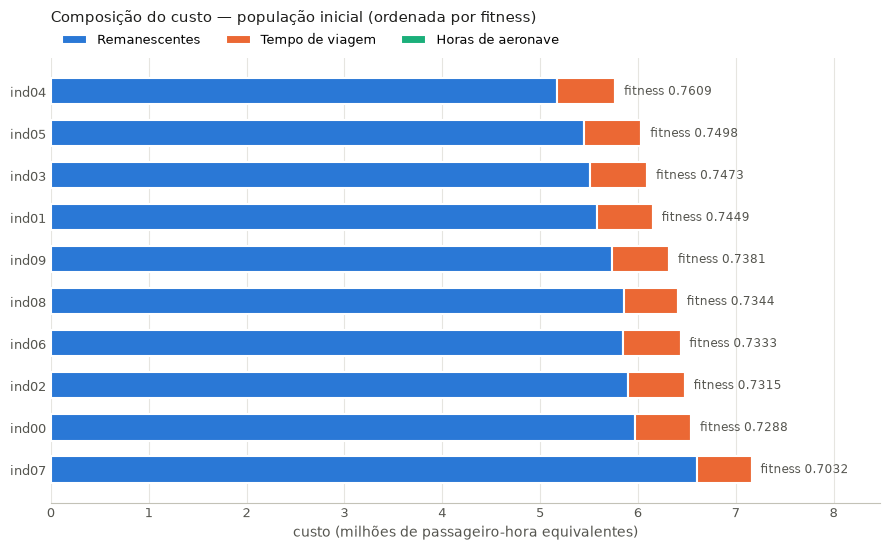

In [35]:
import matplotlib.pyplot as plt

def grafico_custo(avaliacoes, nomes, titulo):
    ordem = sorted(range(len(avaliacoes)), key=lambda i: avaliacoes[i].fitness)
    nomes = [nomes[i] for i in ordem]
    partes = [("Remanescentes", "custo_remanescentes", "#2a78d6"),
              ("Tempo de viagem", "custo_tempo", "#eb6834"),
              ("Horas de aeronave", "custo_aeronaves", "#1baf7a")]

    fig, ax = plt.subplots(figsize=(9, 0.42 * len(nomes) + 1.4))
    esquerda = np.zeros(len(nomes))
    for rotulo, attr, cor in partes:
        vals = np.array([getattr(avaliacoes[i], attr) for i in ordem]) / 1e6
        ax.barh(nomes, vals, left=esquerda, color=cor, label=rotulo, height=0.62,
                edgecolor="white", linewidth=1.5)
        esquerda += vals
    for y, i in enumerate(ordem):
        ax.text(esquerda[y] + esquerda.max() * 0.01, y, f"fitness {avaliacoes[i].fitness:.4f}",
                va="center", fontsize=8.5, color="#55554f")

    ax.set_xlabel("custo (milhões de passageiro-hora equivalentes)", color="#55554f")
    ax.set_xlim(0, esquerda.max() * 1.18)
    ax.set_title(titulo, loc="left", fontsize=11, color="#1f1f1d", pad=26)
    ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9)
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#55554f", labelsize=9, length=0)
    fig.tight_layout()
    plt.show()

nomes_pop = list(tab_av_pop.index)
grafico_custo(avaliacoes, nomes_pop, "Composição do custo — população inicial (ordenada por fitness)")

**(d) Sensibilidade a `MAX_ESCALAS`** — a mesma população avaliada com 0 a 3 escalas permitidas.
Permitir escalas sempre aumenta a fitness: quem não cabe em voo direto passa a ser atendido.
Acima de 2 escalas o ganho é marginal e as viagens ficam longas, por isso `MAX_ESCALAS = 2` é o padrão.

In [36]:
sens = pd.DataFrame({
    f"max_escalas={k}": [a.fitness for a in avaliar_populacao(populacao, max_escalas=k)]
    for k in range(4)
}, index=[f"ind{i:02d}" for i in range(len(populacao))]).round(5)
sens

,max_escalas=0,max_escalas=1,max_escalas=2,max_escalas=3
ind00,0.70019,0.72877,0.72877,0.72877
ind01,0.71867,0.74458,0.74495,0.74495
ind02,0.69205,0.73145,0.73145,0.73145
ind03,0.70950,0.74733,0.74733,0.74733
ind04,0.71900,0.75979,0.76085,0.76085
ind05,0.71156,0.74870,0.74978,0.74978
ind06,0.69436,0.73220,0.73328,0.73328
ind07,0.67312,0.70252,0.70323,0.70323
ind08,0.71261,0.73437,0.73437,0.73437
ind09,0.69774,0.73774,0.73810,0.73810


---
## 4. Algoritmo genético e simulações

*A implementar.*